# Robust diffusion posterior sampling: inverse scattering

**Code attribution.** The sampling, forward-model, and data-loading implementations
used in this notebook are adapted from [InverseBench](https://github.com/devzhk/InverseBench),
copyright (c) 2025 the InverseBench authors, under the MIT License.
See [LICENSE](LICENSE) for the complete copyright and license notice and
[NOTICE.md](NOTICE.md) for source attribution. RDP-specific extensions
are contributed by the RDP authors.

Compare **DPS**, **RDP-DPS**, **LGD**, and **RDP-LGD** on the same corrupted observation.

Install `requirements.txt` first. Place `inv-scatter-5m.pt` in `checkpoints/` and the test LMDB in `data/inv-scatter-test/` (see README). The notebook uses a pretrained diffusion prior; it does not train a model.

In [1]:
from pathlib import Path
import copy
import csv
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

from run import load_config, make_operator, seed_all, image_space
from rdp.data import TestData
from rdp.models import load_model
from rdp.samplers.dps import DPS
from rdp.samplers.lgd import LGD
from evaluate import image_metrics

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


/home/users/y_yiming/miniconda3/envs/ibench/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings
All four runs share the observation, initialization seed, and guidance scale. `STEPS=1000` follows the source VP schedule; a small step count is useful for checking that the pipeline runs, but does not measure reconstruction quality. The optional environment variables let you keep data and weights outside the repository.

In [2]:
SEED = 2026
SAMPLE_ID = 5
STEPS = 1000
GUIDANCE_SCALE = 350.0
MC_SAMPLES = 3
NOISE = "outlier"  # gaussian, student_t, or outlier

config = load_config("scattering")
config["data"]["root"] = os.environ.get("RDP_DATA", "data/inv-scatter-test")
config["data"]["ids"] = str(SAMPLE_ID)
config["checkpoint"] = os.environ.get("RDP_CHECKPOINT", "checkpoints/inv-scatter-5m.pt")
config["noise"]["name"] = NOISE
output = Path("results/demo")
output.mkdir(parents=True, exist_ok=True)
assert Path(config["checkpoint"]).is_file(), "Download the checkpoint listed in README.md."
assert Path(config["data"]["root"]).is_dir(), "Set the path to the inverse-scattering test LMDB."

## One measurement and one pretrained prior
The linear Born operator generates complex observations. Noise is drawn once, before the reconstruction loop.

In [3]:
seed_all(SEED)
operator = make_operator(config, DEVICE)
dataset = TestData(**config["data"])
try:
    target = dataset[0][None].to(DEVICE)
finally:
    dataset.close()
seed_all(SEED + SAMPLE_ID)
observation = operator.observe(target)
net = load_model(config["checkpoint"], "scattering", DEVICE)
print("Target:", tuple(target.shape), "Observation:", tuple(observation.shape))

Target: (1, 1, 128, 128) Observation: (1, 20, 360)


## DPS and LGD, with and without RDP
IMQ uses `c = Quantile_q(|r|)` and `w = (1 + |r|^2 / c^2)^(-1/2)`, followed by mean normalization. The weighted objective uses `w * |r|^2`. The quantile threshold is held fixed during gradient evaluation, while gradients propagate through the residual-dependent weights. The operator evaluates every LGD Monte Carlo sample independently.

In [4]:
reconstructions = {}
rows = []
for name, sampler_class in (("DPS", DPS), ("LGD", LGD)):
    for robust in ("none", "imq"):
        operator.guidance.kind = robust
        seed_all(SEED + SAMPLE_ID)
        kwargs = dict(num_steps=STEPS, guidance_scale=GUIDANCE_SCALE)
        if name == "LGD":
            kwargs["mc_samples"] = MC_SAMPLES
        sampler = sampler_class(net, operator, **kwargs)
        reconstruction = sampler.inference(observation)
        if not torch.isfinite(reconstruction).all():
            raise RuntimeError("Nonfinite reconstruction; check the sampling settings.")
        label = name if robust == "none" else f"RDP-{name}"
        reconstruction = image_space(reconstruction, config)
        metrics = image_metrics(reconstruction, image_space(target, config), "scattering")
        reconstructions[label] = reconstruction.detach().cpu()
        rows.append(dict(method=label, **metrics))
        torch.save({"recon": reconstructions[label], "target": image_space(target, config).cpu(),
                    "observation": observation.detach().cpu(), "seed": SEED,
                    "steps": STEPS, "guidance_scale": GUIDANCE_SCALE,
                    "mc_samples": MC_SAMPLES, "noise": copy.deepcopy(config["noise"]),
                    "guidance": dict(vars(operator.guidance))}, output / f"{label}.pt")
        del sampler

with (output / "metrics.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
header = "| Method | PSNR ↑ | SSIM ↑ | NMAE ↓ |\n|---|---:|---:|---:|"
body = "\n".join(f"| {row['method']} | {row['psnr']:.3f} | {row['ssim']:.3f} | {row['nmae']:.3f} |" for row in rows)
display(Markdown(header + "\n" + body))

LGD: 100%|██████████| 1000/1000 [00:34<00:00, 29.05it/s]


| Method | PSNR ↑ | SSIM ↑ | NMAE ↓ |
|---|---:|---:|---:|
| DPS | 11.223 | 0.555 | 0.866 |
| RDP-DPS | 36.258 | 0.927 | 0.051 |
| LGD | 11.426 | 0.567 | 0.839 |
| RDP-LGD | 31.847 | 0.922 | 0.079 |

## Reconstructions
Results and metrics are saved under `results/demo/`. The notebook contains no precomputed results.

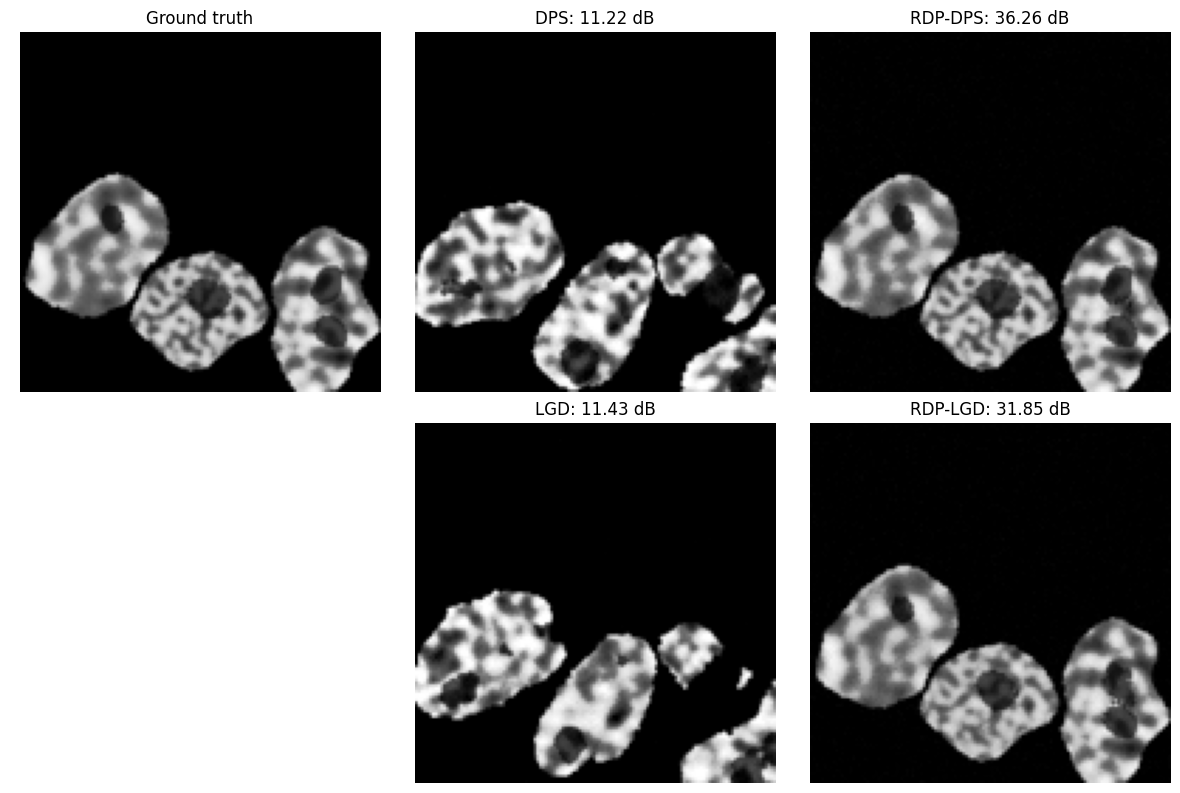

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(image_space(target, config)[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Ground truth")
# axes[1, 0].imshow(observation[0].abs().cpu(), cmap="magma", aspect="auto")
# axes[1, 0].set_title("Corrupted measurement |y|")
for ax, label in zip([axes[0, 1], axes[0, 2], axes[1, 1], axes[1, 2]],
                     ["DPS", "RDP-DPS", "LGD", "RDP-LGD"]):
    ax.imshow(reconstructions[label][0, 0], cmap="gray", vmin=0, vmax=1)
    score = next(row["psnr"] for row in rows if row["method"] == label)
    ax.set_title(f"{label}: {score:.2f} dB")
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(output / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()